# Basics of Mobile Robotics - Project

## Table of Contents

- [Introduction](#introduction)
    - [Group](#group) 
- [Camera and Thymio Connection](#camera-and-thymio-connexion)
- [Vision Processing](#vision-processing)
- [Filtering](#filtering)
- [Navigation](#navigation)
    - [Global Navigation](#global-navigation)
    - [Local Navigation](#local-navigation)
- [Results](#results)
- [Conclusion](#conclusion)

## Introduction 
This project is part of the course *Basics of Mobile Robotics (MICRO-452)* at EPFL and is initially made by group of four students. The class is given by Professor Francesco Mondada from [MOBOTS lab](https://www.epfl.ch/labs/mobots/).

### Goal of the project 
This project aim to implement diverse algorithme seen in course. 
- Autonomous navigation through a specific goal following the optimal path. 
- Unexpected object avoidance. 
- Keep track of the goal if blind through a extended Kalman filter. 
- Be able to reach any position in the predefined map.

### Group
Our team consists of three first-year Master's students in Robotics at EPFL. The work load has been equally separated between members. The final assembly of the code has been done by everyone. 
| Name            | SCIPER | Role                       |
|-----------------|--------|----------------------------|
| Linus  Crugnola | 340864 | Filtering                  |
| Alexis Bollack  | 406474 | Local & Global navigation  |
| Maxime Luyet    | 345770 | Vision                     |



In [50]:
%reload_ext autoreload
%autoreload 2

import sys
import time
sys.path.append('./src')

#from filtering import *
from src.vision import Vision 
from src.global_navigation import GlobalNavigation
from src.local_navigation import LocalNavigation
from src.filtering import KalmanFilter
#from utils import utils

In [51]:
#Constants
CAM_ID = 0

In [82]:
vision = Vision(CAM_ID)
vision.message_from_vision()

#Declare your other instance here 

Vision module is correctly linked.


## Camera and Thymio connexion 

Here we setup the connexion to the other perhiphericals. 

### Camera connexion 

In [76]:
#ERREUR, la condition vision.webcam_connextion() 
#est exécutée 2 fois pour une raison inconnue 
try:
    print("Connexion to camera ...")

    if not vision.webcam_connextion():
        print("Failed to connect to camera")
        exit(1)
    else:
        print("Webcam connected")

    # start_time = time.time()
    # while time.time() - start_time < 3:
    #     original_frame = vision._get_original_frame()
    #     utils.display_frames(original_frame, None, None)
except KeyboardInterrupt: 
    print("Program interrupted by user.")
    pass
finally: 
    vision.disconnect_webcam()

Connexion to camera ...
Webcam connected successfully!
Webcam connected
Webcam deconnected
Webcam connected successfully!
Webcam connected
Webcam deconnected


In [174]:
vision.webcam_connextion()

Webcam connected successfully!


True

In [160]:
vision.disconnect_webcam()

Webcam deconnected


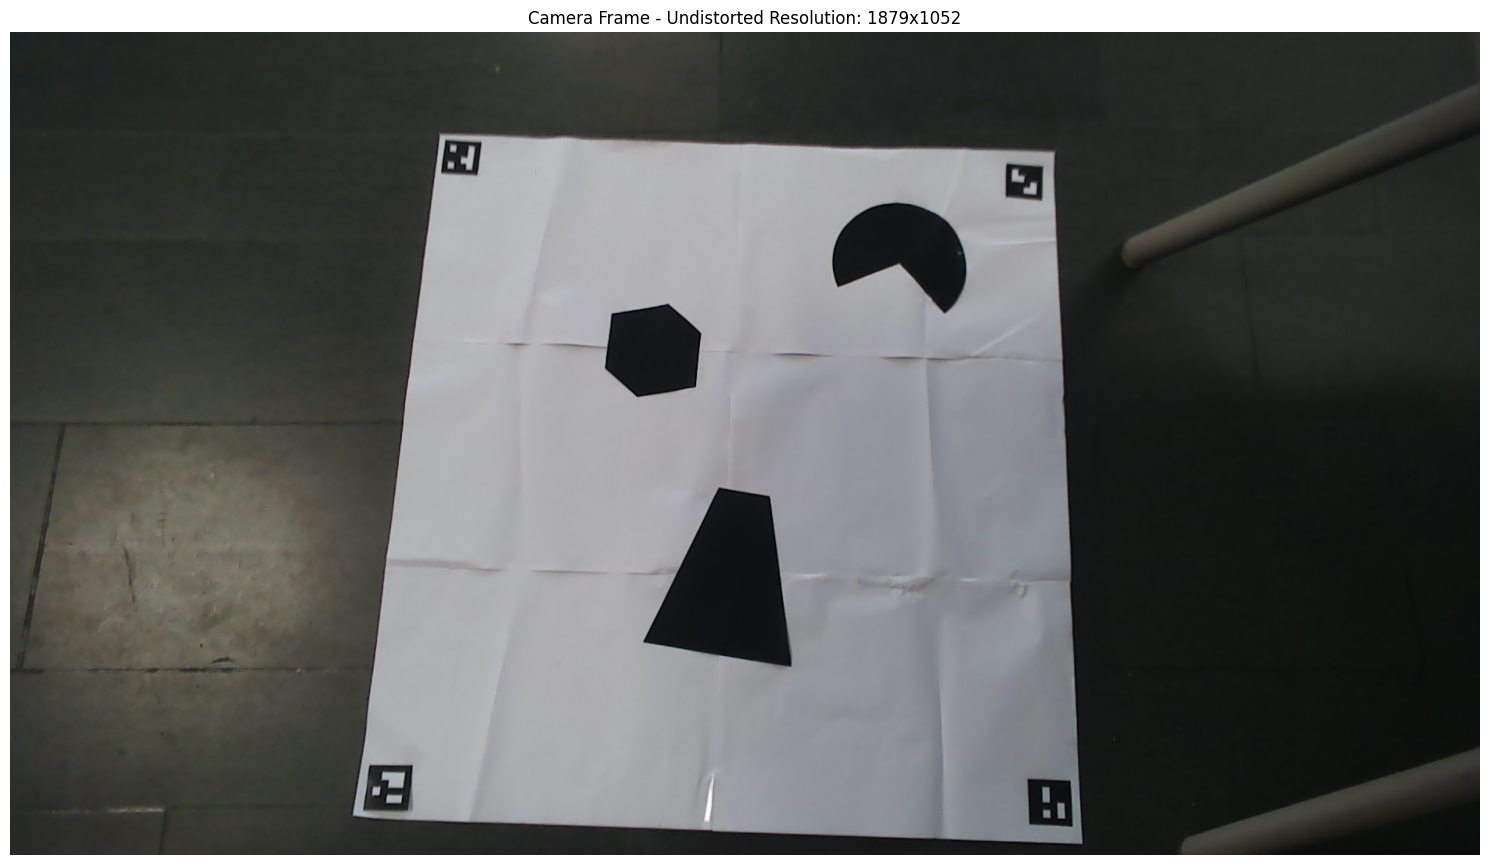

Frame shape (Height x Width x Channels): (1052, 1879, 3)
Frame captured successfully!


In [204]:
#RETESEER LES VALEURS DE LA CAMERA 

#=============================================
#Test of camera capture and undistortion
#=============================================

import matplotlib.pyplot as plt

# Capture frame from camera (undistorted frame)
frame = vision._get_frame()

if frame is not None:
    # Convert BGR (OpenCV) to RGB (matplotlib)
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # Display the image
    plt.figure(figsize=(15, 10))
    plt.imshow(frame_rgb)
    plt.title(f"Camera Frame - Undistorted Resolution: {frame.shape[1]}x{frame.shape[0]}")
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    print(f"Frame shape (Height x Width x Channels): {frame.shape}")
    print(f"Frame captured successfully!")
else:
    print("Failed to capture frame")

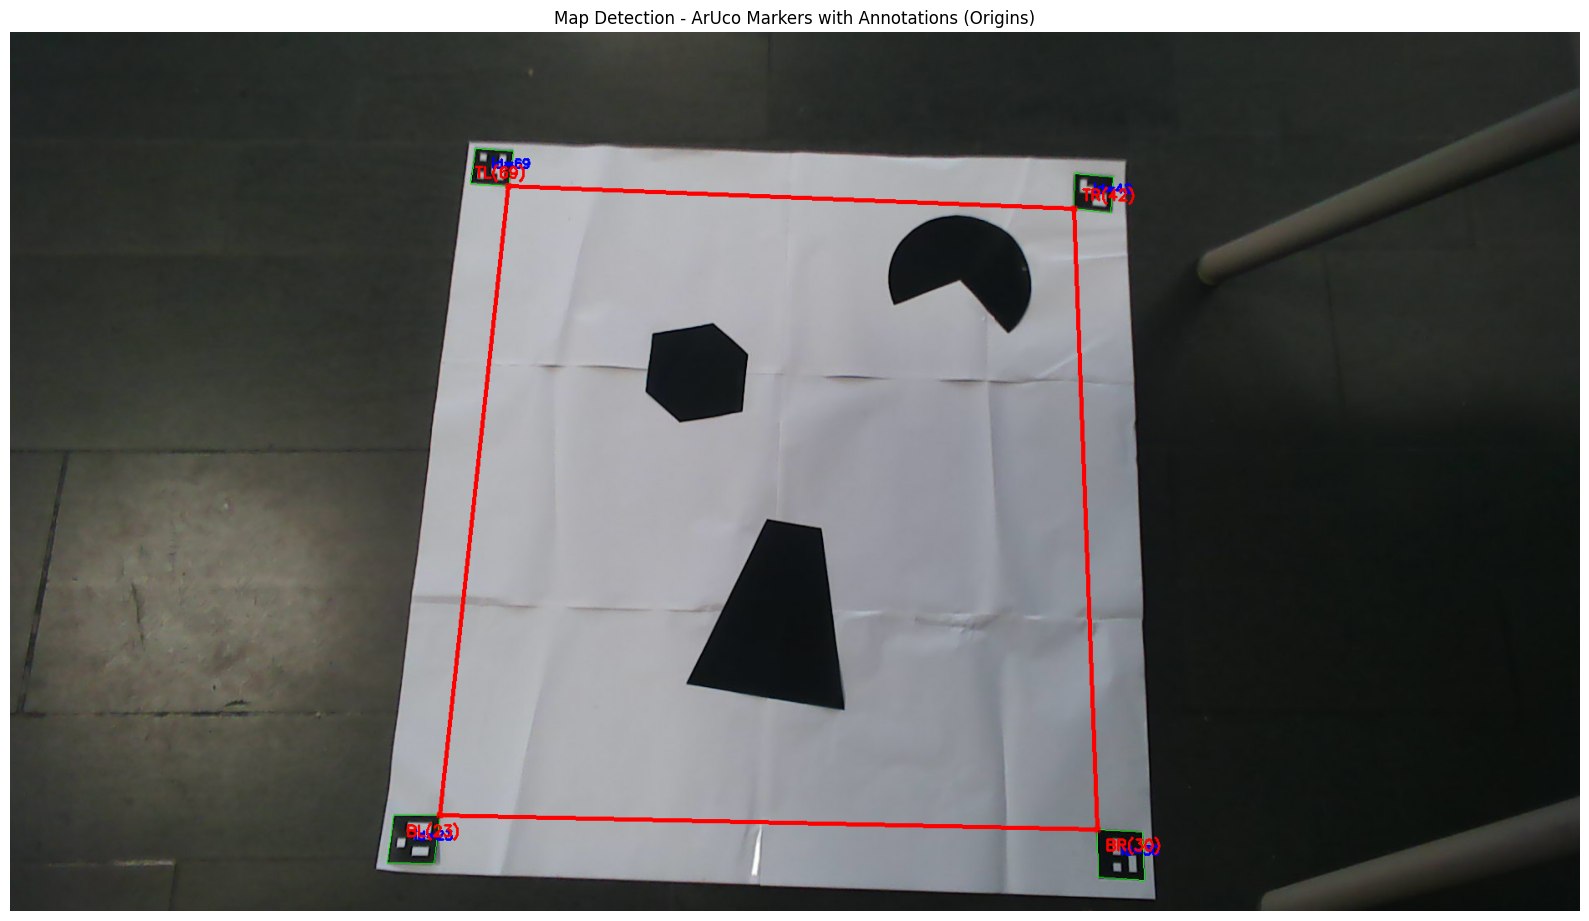

Detected ArUco marker origin positions (Top-Left corner):
  TL (69): (596.0, 184.0)
  TR (42): (1273.0, 211.0)
  BL (23): (514.0, 937.0)
  BR (30): (1301.0, 954.0)


In [206]:
#============================================
#Test of map detection with aruco markers
#============================================

import cv2
import matplotlib.pyplot as plt
import numpy as np
from src import utils

# Capture frame
before_map_crop = vision._get_frame()

if before_map_crop is not None:
    # Create a copy for drawing (before detection modifies the frame)
    frame_with_markers = before_map_crop.copy()
    
    # Detect ArUco markers (this will draw on the copy)
    img, corner_pos = vision._detect_map_markers(frame_with_markers)
    
    if corner_pos is not None:
        # Extract the 4 corner markers from dictionary in correct order [TL, TR, BL, BR]
        corners_array = np.array([
            corner_pos[69],  # TL
            corner_pos[42],  # TR
            corner_pos[23],  # BL
            corner_pos[30]   # BR
        ])
        
        # Draw red borders connecting the 4 corner markers using utils
        img = utils.draw_red_line_in_image(corners_array, img)
        
        # Convert BGR to RGB for matplotlib
        frame_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        # Display the result
        plt.figure(figsize=(16, 10))
        plt.imshow(frame_rgb)
        plt.title("Map Detection - ArUco Markers with Annotations (Origins)")
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        # Print marker positions (origins = top-left corners)
        print("Detected ArUco marker origin positions (Top-Left corner):")
        for marker_id in [69, 42, 23, 30]:
            if marker_id in corner_pos:
                x, y = corner_pos[marker_id]
                marker_name = {69: "TL", 42: "TR", 23: "BL", 30: "BR"}[marker_id]
                print(f"  {marker_name} ({marker_id}): ({x:.1f}, {y:.1f})")
        
    else:
        print("Failed to detect all ArUco markers!")
        print("Make sure all 6 markers are visible: 69, 42, 23, 30 (corners), 78 (robot), 53 (goal)")
else:
    print("Failed to capture frame")

Capturing frame and computing bird's eye view...


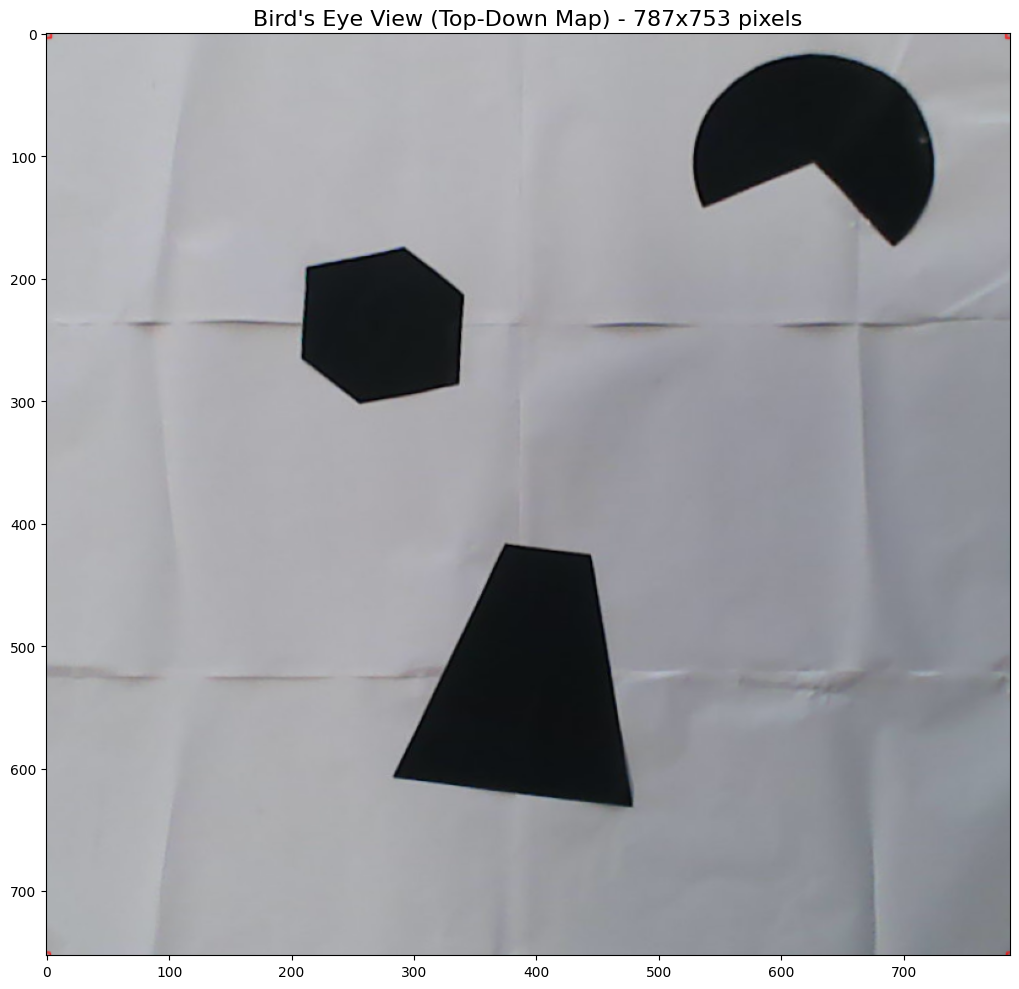


 Bird's eye view extracted successfully!
  Map dimensions: 787 x 753 pixels


In [209]:
#============================================
#Test: Bird's Eye View (Top-Down Map)
#============================================

import cv2
import matplotlib.pyplot as plt
import numpy as np

print("Capturing frame and computing bird's eye view...")

# Get bird's eye view directly (captures frame internally)
birds_eye_view = vision.get_birds_eye_view()

if birds_eye_view is not None:
    # Convert BGR to RGB for matplotlib display
    map_rgb = cv2.cvtColor(birds_eye_view, cv2.COLOR_BGR2RGB)
    
    # Get map dimensions
    height, width = birds_eye_view.shape[:2]
    
    # Display the bird's eye view map
    plt.figure(figsize=(14, 10))
    plt.imshow(map_rgb)
    plt.title(f"Bird's Eye View (Top-Down Map) - {width}x{height} pixels", fontsize=16)
    # plt.xlabel("X (pixels)", fontsize=12)
    # plt.ylabel("Y (pixels)", fontsize=12)
    # plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"\n Bird's eye view extracted successfully!")
    print(f"  Map dimensions: {width} x {height} pixels")  
else:
    print("✗ Failed to get bird's eye view.")
    print("  Make sure:")
    print("  - Camera is connected")
    print("  - All 4 corner markers are visible (IDs: 42, 30, 69, 23)")
    print("  - Markers are not obscured or too close to frame edges")


In [210]:
#============================================
#Test: Obstacle detection on bird's eye view
#============================================

print("Detecting obstacles and generating occupancy grid...")

# Get bird's eye view
birds_eye_view = vision.get_birds_eye_view()

if birds_eye_view is not None:
    # Detect obstacles and create occupancy grid
    occupancy_grid = vision.detect_obstacles(birds_eye_view)
    
    if occupancy_grid is not None:
        # Visualize using the vision class method
        vision.visualize_occupancy_grid(occupancy_grid, "Occupancy Grid Visualization")
        
        # Print statistics
        total_cells = occupancy_grid.size
        obstacle_cells = np.sum(occupancy_grid)
        free_cells = total_cells - obstacle_cells
        obstacle_percentage = (obstacle_cells / total_cells) * 100
        
        print(f"\n✓ Occupancy grid generated successfully!")
        print(f"  Grid size: {occupancy_grid.shape[1]} x {occupancy_grid.shape[0]} cells")
        print(f"  Total cells: {total_cells}")
        print(f"  Obstacle cells: {obstacle_cells} ({obstacle_percentage:.1f}%)")
        print(f"  Free cells: {free_cells} ({100-obstacle_percentage:.1f}%)")
    else:
        print("✗ Failed to generate occupancy grid.")
else:
    print("✗ Failed to get bird's eye view.")

Detecting obstacles and generating occupancy grid...

✓ Occupancy grid generated successfully!
  Grid size: 787 x 753 cells
  Total cells: 592611
  Obstacle cells: 179018 (30.2%)
  Free cells: 413593 (69.8%)

✓ Occupancy grid generated successfully!
  Grid size: 787 x 753 cells
  Total cells: 592611
  Obstacle cells: 179018 (30.2%)
  Free cells: 413593 (69.8%)
